# Imdb top 250 analysis

In this part of the exam, we will gain some insights from the data of the top 250 movies on Imdb, that we obtained in the first part of the exam.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Task 1:
- Create a pandas DataFrame by reading the .json file you created in the first part of the exam. 
- show the first 15 rows of the DataFrame.

In [95]:
MOVIES_JSON_FILE = "failsafe.json"
df = pd.read_json(MOVIES_JSON_FILE) 

df.head(15)

,title,year,rating,directors,movie_stars
0,The Shawshank Redemption,1994,9.3,[Frank Darabont],"[Tim Robbins, Morgan Freeman, Bob Gunton]"
1,The Godfather,1972,9.2,[Francis Ford Coppola],"[Marlon Brando, Al Pacino, James Caan]"
2,The Dark Knight,2008,9.0,[Christopher Nolan],"[Christian Bale, Heath Ledger, Aaron Eckhart]"
3,The Godfather Part II,1974,9.0,[Francis Ford Coppola],"[Al Pacino, Robert De Niro, Robert Duvall]"
4,12 Angry Men,1957,9.0,[Sidney Lumet],"[Henry Fonda, Lee J. Cobb, Martin Balsam]"
5,The Lord of the Rings: The Return of the King,2003,9.0,[Peter Jackson],"[Elijah Wood, Viggo Mortensen, Ian McKellen]"
6,Schindler's List,1993,9.0,[Steven Spielberg],"[Liam Neeson, Ralph Fiennes, Ben Kingsley]"
7,Pulp Fiction,1994,8.9,[Quentin Tarantino],"[John Travolta, Uma Thurman, Samuel L. Jackson]"
8,The Lord of the Rings: The Fellowship of the Ring,2001,8.9,[Peter Jackson],"[Elijah Wood, Ian McKellen, Orlando Bloom]"
9,"The Good, the Bad and the Ugly",1966,8.8,[Sergio Leone],"[Clint Eastwood, Eli Wallach, Lee Van Cleef]"


### Task 2:
Show all the movies that were released in the year 2000.

In [96]:
df_2000 = df[df['year'] == 2000]
df_2000

,title,year,rating,directors,movie_stars
34,Gladiator,2000,8.5,[Ridley Scott],"[Russell Crowe, Joaquin Phoenix, Connie Nielsen]"
56,Memento,2000,8.4,[Christopher Nolan],"[Guy Pearce, Carrie-Anne Moss, Joe Pantoliano]"
90,Requiem for a Dream,2000,8.3,[Darren Aronofsky],"[Ellen Burstyn, Jared Leto, Jennifer Connelly]"
120,Snatch,2000,8.2,[Guy Ritchie],"[Jason Statham, Brad Pitt, Stephen Graham]"
244,Amores Perros,2000,8.0,[Alejandro G. Iñárritu],"[Emilio Echevarría, Gael García Bernal, Goya T..."


### Task 3: Best of the 80s
- Find the top **10** highest-rated movies released between 1980 and 1989. Include only the columns  `title`, `year`, and `ranking`.


In [97]:
df.loc[(df['year'] >= 1980) & (df['year'] <= 1989)].sort_values(by='rating', ascending=False)[['title', 'year', 'rating']].head(10)

,title,year,rating
14,Star Wars: Episode V - The Empire Strikes Back,1980,8.7
39,Grave of the Fireflies,1988,8.5
48,Cinema Paradiso,1988,8.5
29,Back to the Future,1985,8.5
58,Raiders of the Lost Ark,1981,8.4
66,The Shining,1980,8.4
68,Aliens,1986,8.4
72,Amadeus,1984,8.4
78,Das Boot,1981,8.4
89,Come and See,1985,8.4


### Task 4: Decades with most entries

![alt text](best_decades.jpg)

- Find the top 5 decades based on the number of movies released in that decade: the output should look something like this:

```plaintext
decade
2000    48
2010    44
1990    40
1980    26
1950    22
```

In [98]:
df['decade'] = df['year'] // 10 * 10
df_top_decade_n = df.groupby('decade').size().sort_values(ascending=False).head(5)

display(df_top_decade_n)

decade
2000    48
2010    44
1990    40
1980    26
1950    22
dtype: int64

### Task 5:

### TODO maybe dont include this task

Make a csv file, where the first columns are: `movie_stars`, `movie_count`, `average_rating`.

Sort the csv file first by the number of movies, then by the average ranking.

The output should look like this:

```plaintext
movie_stars,movie_count,average_rating
Robert De Niro,9,8.366666666666667
Harrison Ford,6,8.383333333333333
Leonardo DiCaprio,6,8.383333333333333
Tom Hanks,6,8.450000000000001
...
```

In [99]:
df_exploded = df.explode('movie_stars')

df_star_movies = df_exploded.groupby('movie_stars').agg({'title': 'count', 'rating': 'mean'}).sort_values(by=['title', 'rating'], ascending=[False, False])

df_star_movies.columns = ['movie_count', 'average_rating']

display(df_star_movies)

df_star_movies.to_csv('movie_appereances.csv')

,movie_count,average_rating
movie_stars,,
Robert De Niro,9,8.366667
Tom Hanks,6,8.450000
Harrison Ford,6,8.383333
Leonardo DiCaprio,6,8.383333
Christian Bale,5,8.440000
...,...,...
Chris Elliott,1,8.000000
Craig T. Nelson,1,8.000000
Emilio Echevarría,1,8.000000


### Task 6: Iconic director/actor duos

![alt text](duos.jpg)

Some film directors and actors have collaborated together numerous times and have become noteworthy for their partnerships.

- Find the top 5 director/actor duos who have worked together in the most number of movies. 

In [100]:
df_explode = df.explode('directors')
df_explode = df_explode.explode('movie_stars')

df_explode['director_actor'] = df_explode['directors'] + ' - ' + df_explode['movie_stars']

df_top_director_actor = df_explode['director_actor'].value_counts().head(5)

df_top_director_actor

director_actor
Charles Chaplin - Charles Chaplin     5
Christopher Nolan - Christian Bale    4
Martin Scorsese - Robert De Niro      4
Akira Kurosawa - Toshirô Mifune       4
Peter Jackson - Ian McKellen          3
Name: count, dtype: int64

### Task 7: Rating distribution

- Visualize the distribution of the rankings of the movies. 
Recreate the following plot using seaborn and matplotlib:

![alt text](rating_density.png)

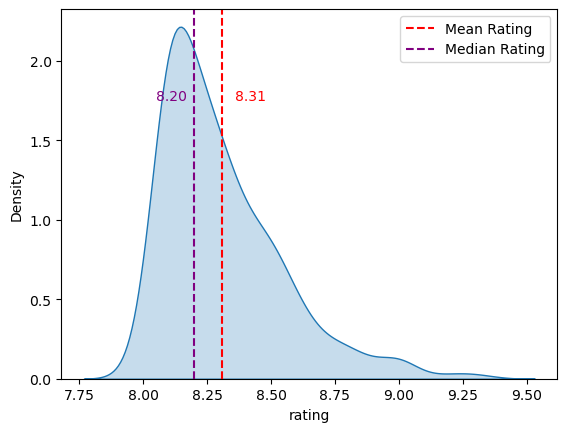

In [101]:
sns.kdeplot(df['rating'], fill=True)

plt.axvline(df['rating'].mean(), color='red', linestyle='--', label='Mean Rating')
plt.axvline(df['rating'].median(), color='purple', linestyle='--', label='Median Rating')

plt.text(df['rating'].mean() + 0.05, 1.75, f"{df['rating'].mean():.2f}", color='red')
plt.text(df['rating'].median() - 0.15, 1.75, f"{df['rating'].median():.2f}", color='purple')
plt.legend()